In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/SpamAssasin.csv
/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Nazario.csv
/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Nigerian_Fraud.csv
/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/CEAS_08.csv
/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Enron.csv
/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Ling.csv
/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/phishing_email.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from imblearn.over_sampling import SMOTE

In [3]:
#spam = pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/SpamAssasin.csv')
ceas = pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/CEAS_08.csv')
#ling = pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Ling.csv')
#enron = pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Enron.csv')
#nazario= pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Nazario.csv')
#nigerian= pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/Nigerian_Fraud.csv')
#phishing = pd.read_csv('/kaggle/input/datasets/naserabdullahalam/phishing-email-dataset/phishing_email.csv')


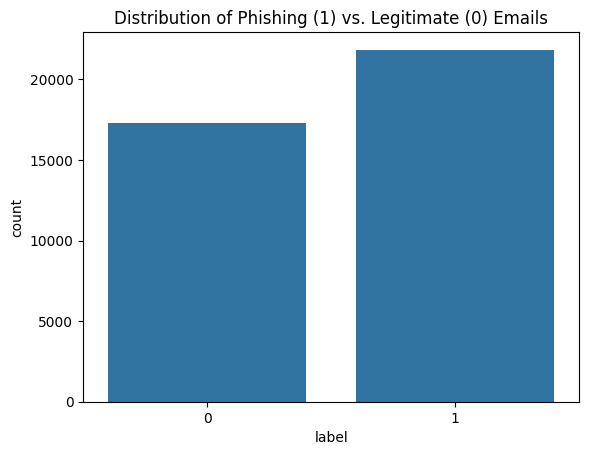

Shape: (39154, 7)
Columns: ['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls']

Label distribution:
label
1    21842
0    17312
Name: count, dtype: int64

Missing values:
sender        0
receiver    462
date          0
subject      28
body          0
label         0
urls          0
dtype: int64

Duplicates: 0


,sender,receiver,date,subject,body,label,urls
0,Young Esposito <Young@iworld.de>,user4@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 16:31:02 -0700",Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1,1
1,Mok <ipline's1983@icable.ph>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 18:31:03 -0500",Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1,1
2,Daily Top 10 <Karmandeep-opengevl@universalnet...,user2.9@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 20:28:00 -1200",CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1,1
3,Michael Parker <ivqrnai@pobox.com>,SpamAssassin Dev <xrh@spamassassin.apache.org>,"Tue, 05 Aug 2008 17:31:20 -0600",Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...,0,1
4,Gretchen Suggs <externalsep1@loanofficertool.com>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 19:31:21 -0400",SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7...,1,1


In [4]:
sns.countplot(x='label', data=ceas)
plt.title('Distribution of Phishing (1) vs. Legitimate (0) Emails')
plt.show()

print(f'Shape: {ceas.shape}')
print(f'Columns: {list(ceas.columns)}')
print('\nLabel distribution:')
print(ceas['label'].value_counts())
print('\nMissing values:')
print(ceas.isnull().sum())
print(f'\nDuplicates: {ceas.duplicated().sum()}')

ceas.head()